# Homework 7

## 1. Multi-class and Multi-label Classification Using Support Vector Machines

### (a)

In [1]:
import pandas as pd

df = pd.read_csv("Frogs_MFCCs.csv")

print("Dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())

df.head()

Dataset shape: (7195, 26)
Missing values: 0


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


In [2]:
from sklearn.model_selection import train_test_split

label_cols = ["Family", "Genus", "Species"]

X = df.drop(columns=label_cols + ["RecordID"])
y = df[label_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (5036, 22)
Testing features: (2159, 22)
Training labels: (5036, 3)
Testing labels: (2159, 3)


### (b)
#### i

In [3]:
import numpy as np


def evaluate_multilabel(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # Exact match requires all three labels to be correct.
    correct = y_true == y_pred

    return {
        "Exact Match": correct.all(axis=1).mean(),
        "Hamming Score": correct.mean(),
        "Hamming Loss": (~correct).mean()
    }

#### ii

In [4]:
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "estimator__C": [0.01, 0.1, 1, 10, 100, 1000],
    "estimator__gamma": [0.001, 0.01, 0.1, 1, 10]
}

# Use the same folds when comparing the classifiers.
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

rbf_models = {}
rbf_predictions = pd.DataFrame(index=y_test.index)
cv_results = []

# Tune a separate classifier for Family, Genus, and Species.
for label in label_cols:
    print(f"Training {label}...", flush=True)

    model = OneVsRestClassifier(SVC(kernel="rbf"))

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X_train, y_train[label])

    rbf_models[label] = search.best_estimator_
    rbf_predictions[label] = search.predict(X_test)

    cv_results.append({
        "Label": label,
        "Best C": search.best_params_["estimator__C"],
        "Best gamma": search.best_params_["estimator__gamma"],
        "CV Accuracy": search.best_score_
    })

    print(f"{label} completed.", flush=True)

pd.DataFrame(cv_results)

Training Family...
Family completed.
Training Genus...
Genus completed.
Training Species...
Species completed.


,Label,Best C,Best gamma,CV Accuracy
0,Family,1000,1,0.991659
1,Genus,10,1,0.991064
2,Species,10,1,0.990074


In [5]:
from sklearn.metrics import accuracy_score

label_accuracy = pd.DataFrame({
    "Label": label_cols,
    "Test Accuracy": [
        accuracy_score(y_test[label], rbf_predictions[label])
        for label in label_cols
    ]
})

display(label_accuracy)

rbf_metrics = evaluate_multilabel(
    y_test[label_cols], rbf_predictions[label_cols]
)

rbf_results = pd.DataFrame(
    [rbf_metrics],
    index=["Gaussian SVM (raw features)"]
)

display(rbf_results)

,Label,Test Accuracy
0,Family,0.995831
1,Genus,0.990273
2,Species,0.990736


,Exact Match,Hamming Score,Hamming Loss
Gaussian SVM (raw features),0.987494,0.99228,0.00772


#### iii

In [6]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

l1_param_grid = {"svm__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]}

l1_models = {}
l1_predictions = pd.DataFrame(index=y_test.index)
l1_cv_results = []

for label in label_cols:
    print(f"Training {label}...", flush=True)

    # Fit the scaler inside each training fold.
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            multi_class="ovr",
            max_iter=100000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        estimator=model,
        param_grid=l1_param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X_train, y_train[label])

    l1_models[label] = search.best_estimator_
    l1_predictions[label] = search.predict(X_test)

    l1_cv_results.append({
        "Label": label,
        "Best C": search.best_params_["svm__C"],
        "CV Accuracy": search.best_score_
    })

    print(f"{label} completed.", flush=True)

display(pd.DataFrame(l1_cv_results))

Training Family...
Family completed.
Training Genus...
Genus completed.
Training Species...
Species completed.


,Label,Best C,CV Accuracy
0,Family,10,0.941223
1,Genus,1000,0.951750
2,Species,10,0.960682


In [7]:
l1_label_accuracy = pd.DataFrame({
    "Label": label_cols,
    "Test Accuracy": [
        accuracy_score(y_test[label], l1_predictions[label])
        for label in label_cols
    ]
})

display(l1_label_accuracy)

l1_metrics = evaluate_multilabel(
    y_test[label_cols], l1_predictions[label_cols]
)

comparison = pd.DataFrame(
    [rbf_metrics, l1_metrics],
    index=[
        "Gaussian SVM (raw features)",
        "L1 Linear SVM (standardized)"
    ]
)

display(comparison)

,Label,Test Accuracy
0,Family,0.928208
1,Genus,0.941640
2,Species,0.959240


,Exact Match,Hamming Score,Hamming Loss
Gaussian SVM (raw features),0.987494,0.992280,0.007720
L1 Linear SVM (standardized),0.912459,0.943029,0.056971


#### iv

In [8]:
%pip install imbalanced-learn

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

smote_models = {}
smote_predictions = pd.DataFrame(index=y_test.index)
smote_cv_results = []

for label in label_cols:
    print(f"Training {label} with SMOTE...", flush=True)

    # Apply SMOTE only to the training portion of each fold.
    model = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            multi_class="ovr",
            max_iter=100000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        estimator=model,
        param_grid=l1_param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X_train, y_train[label])

    smote_models[label] = search.best_estimator_
    smote_predictions[label] = search.predict(X_test)

    smote_cv_results.append({
        "Label": label,
        "Best C": search.best_params_["svm__C"],
        "CV Accuracy": search.best_score_
    })

    print(f"{label} completed.", flush=True)

display(pd.DataFrame(smote_cv_results))

Note: you may need to restart the kernel to use updated packages.
Training Family with SMOTE...
Family completed.
Training Genus with SMOTE...
Genus completed.
Training Species with SMOTE...
Species completed.


,Label,Best C,CV Accuracy
0,Family,10,0.923156
1,Genus,1,0.912837
2,Species,10,0.958103


In [9]:
smote_metrics = evaluate_multilabel(
    y_test[label_cols], smote_predictions[label_cols]
)

comparison = pd.DataFrame(
    [rbf_metrics, l1_metrics, smote_metrics],
    index=[
        "Gaussian SVM",
        "L1 Linear SVM",
        "L1 Linear SVM + SMOTE"
    ]
)

display(comparison)

,Exact Match,Hamming Score,Hamming Loss
Gaussian SVM,0.987494,0.992280,0.007720
L1 Linear SVM,0.912459,0.943029,0.056971
L1 Linear SVM + SMOTE,0.853636,0.923113,0.076887


In [10]:
from sklearn.metrics import balanced_accuracy_score, f1_score

predictions = {
    "Gaussian SVM": rbf_predictions,
    "L1 Linear SVM": l1_predictions,
    "L1 Linear SVM + SMOTE": smote_predictions
}

rows = []

for model_name, pred in predictions.items():
    for label in label_cols:
        rows.append({
            "Model": model_name,
            "Label": label,
            "Accuracy": accuracy_score(y_test[label], pred[label]),
            "Balanced Accuracy": balanced_accuracy_score(
                y_test[label], pred[label]
            ),
            "Macro F1": f1_score(
                y_test[label], pred[label],
                average="macro",
                zero_division=0
            )
        })

label_comparison = pd.DataFrame(rows)
display(label_comparison)

,Model,Label,Accuracy,Balanced Accuracy,Macro F1
0,Gaussian SVM,Family,0.995831,0.979751,0.987471
1,Gaussian SVM,Genus,0.990273,0.965606,0.972483
2,Gaussian SVM,Species,0.990736,0.974971,0.978226
3,L1 Linear SVM,Family,0.928208,0.690223,0.682802
4,L1 Linear SVM,Genus,0.941640,0.769036,0.809147
5,L1 Linear SVM,Species,0.959240,0.894759,0.906036
6,L1 Linear SVM + SMOTE,Family,0.909217,0.913069,0.794718
7,L1 Linear SVM + SMOTE,Genus,0.902270,0.916202,0.802405
8,L1 Linear SVM + SMOTE,Species,0.957851,0.927814,0.904153


Gaussian SVM performed best across all three targets in accuracy,
balanced accuracy, and macro F1.

Adding SMOTE to the L1 linear SVM improved balanced accuracy for
all three targets. The largest improvement was for Family, from
0.6902 to 0.9131, suggesting better recognition of underrepresented
classes.

However, SMOTE reduced overall accuracy for Family and Genus.
Macro F1 improved for Family but decreased slightly for Genus
and Species. Therefore, SMOTE helped balance class recall, but
did not consistently improve overall performance.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a)

In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

X_cluster = X.to_numpy()


def select_kmeans(X_data, seed):
    scores = []
    best_score = -np.inf
    best_model = None

    # Keep the model with the highest Calinski-Harabasz score.
    for k in range(2, 51):
        model = KMeans(
            n_clusters=k, n_init=10, random_state=seed
        )

        cluster_ids = model.fit_predict(X_data)
        score = calinski_harabasz_score(X_data, cluster_ids)

        scores.append({
            "k": k,
            "CH Score": score
        })

        if score > best_score:
            best_score = score
            best_model = model

    return best_model, pd.DataFrame(scores)


best_kmeans, ch_results = select_kmeans(X_cluster, seed=42)

print("Selected k:", best_kmeans.n_clusters)

display(ch_results.sort_values("CH Score", ascending=False).head(10))

Selected k: 2


,k,CH Score
0,2,3680.741349
1,3,3157.638923
2,4,2756.474989
3,5,2628.969989
4,6,2390.208399
5,7,2235.984884
6,8,2117.487050
7,9,2049.083055
8,10,1974.157009
9,11,1904.959459


### (b)

In [12]:
def assign_majority_labels(cluster_ids, true_labels):
    data = true_labels.reset_index(drop=True).copy()
    data["Cluster"] = cluster_ids

    # Choose the most common label for each target within a cluster.
    majority_labels = (
        data.groupby("Cluster")[label_cols]
        .agg(lambda column: column.mode().iloc[0])
    )

    assigned_labels = majority_labels.loc[cluster_ids, label_cols].reset_index(drop=True)

    cluster_summary = majority_labels.copy()
    cluster_summary.insert(0, "Size", data.groupby("Cluster").size())

    return assigned_labels, cluster_summary


cluster_predictions, cluster_summary = assign_majority_labels(
    best_kmeans.labels_, y
)

display(cluster_summary)

,Size,Family,Genus,Species
Cluster,,,,
0,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,3597,Hylidae,Hypsiboas,HypsiboasCordobae


### (c) 

In [13]:
def evaluate_clustering(true_labels, assigned_labels):
    true_array = np.asarray(true_labels)
    assigned_array = np.asarray(assigned_labels)

    mismatches = true_array != assigned_array

    # Distance counts wrong labels per sample; loss is the wrong-label fraction.
    avg_distance = mismatches.sum(axis=1).mean()
    hamming_loss = mismatches.mean()

    return {
        "Average Hamming Distance": avg_distance,
        "Hamming Score": 1 - hamming_loss,
        "Hamming Loss": hamming_loss
    }


cluster_metrics = evaluate_clustering(
    y[label_cols], cluster_predictions[label_cols]
)

display(pd.DataFrame([cluster_metrics], index=["K-means"]))

,Average Hamming Distance,Hamming Score,Hamming Loss
K-means,0.895622,0.701459,0.298541


In [14]:
mc_results = []

# Repeat the full k search with a different seed in each run.
for run in range(50):
    print(f"Starting run {run + 1}/50...", flush=True)

    model, _ = select_kmeans(X_cluster, seed=run)

    assigned_labels, _ = assign_majority_labels(model.labels_, y)

    metrics = evaluate_clustering(
        y[label_cols], assigned_labels[label_cols]
    )

    mc_results.append({
        "Run": run + 1,
        "Selected k": model.n_clusters,
        **metrics
    })

    print(
        f"Completed: k={model.n_clusters}, "
        f"Average Hamming Distance="
        f"{metrics['Average Hamming Distance']:.4f}",
        flush=True
    )

mc_results = pd.DataFrame(mc_results)

display(mc_results)

Starting run 1/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 2/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 3/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 4/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 5/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 6/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 7/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 8/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 9/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 10/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 11/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 12/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 13/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 14/50...
Completed: k=2, Average Hamming Distance=0.8956
Starting run 15/50...
Complet

,Run,Selected k,Average Hamming Distance,Hamming Score,Hamming Loss
0,1,2,0.895622,0.701459,0.298541
1,2,2,0.895622,0.701459,0.298541
2,3,2,0.895622,0.701459,0.298541
3,4,2,0.895622,0.701459,0.298541
4,5,2,0.895622,0.701459,0.298541
5,6,2,0.895622,0.701459,0.298541
6,7,2,0.895622,0.701459,0.298541
7,8,2,0.895622,0.701459,0.298541
8,9,2,0.895622,0.701459,0.298541
9,10,2,0.895622,0.701459,0.298541


In [15]:
metric_cols = [
    "Average Hamming Distance",
    "Hamming Score",
    "Hamming Loss"
]

# Report the sample standard deviation across the 50 runs.
mc_summary = pd.DataFrame({
    "Mean": mc_results[metric_cols].mean(),
    "Standard Deviation": mc_results[metric_cols].std(ddof=1)
})

display(mc_summary)

print("Frequency of selected k:")
display(
    mc_results["Selected k"]
    .value_counts()
    .sort_index()
    .rename_axis("k")
    .to_frame("Number of Runs")
)

,Mean,Standard Deviation
Average Hamming Distance,0.895622,1.121495e-16
Hamming Score,0.701459,1.121495e-16
Hamming Loss,0.298541,5.607473e-17


Frequency of selected k:


,Number of Runs
k,
2,50


## ISLR 12.6.2

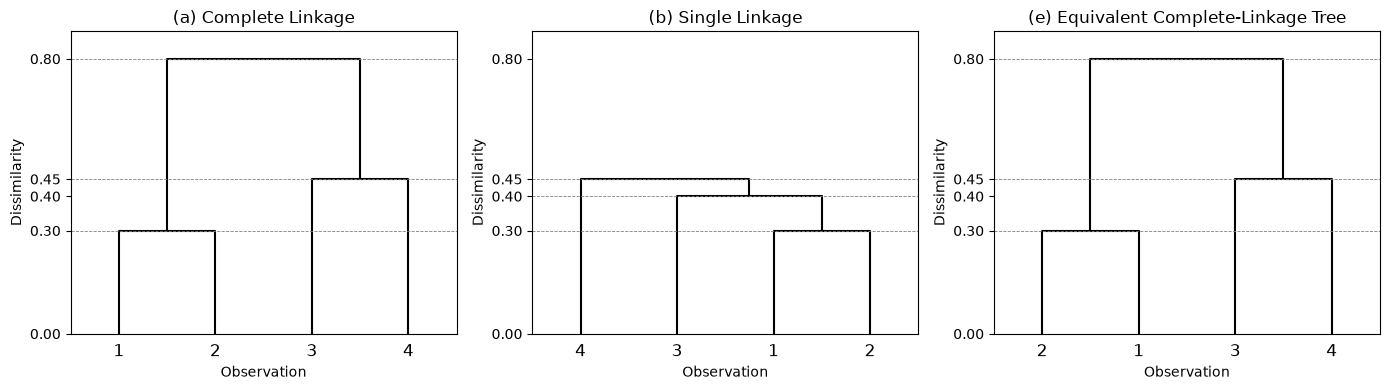

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# scipy expects pairwise distances in this order: d12, d13, d14, d23, d24, d34.
distances = np.array([0.30, 0.40, 0.70, 0.50, 0.80, 0.45])

complete_tree = linkage(distances, method="complete")
single_tree = linkage(distances, method="single")

# Reverse the first pair to draw the same clustering with leaves 1 and 2 swapped.
equivalent_tree = complete_tree.copy()
equivalent_tree[0, :2] = equivalent_tree[0, :2][::-1]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

trees = [complete_tree, single_tree, equivalent_tree]
titles = [
    "(a) Complete Linkage",
    "(b) Single Linkage",
    "(e) Equivalent Complete-Linkage Tree"
]

for ax, tree, title in zip(axes, trees, titles):
    dendrogram(
        tree,
        labels=["1", "2", "3", "4"],
        color_threshold=0,
        above_threshold_color="black",
        ax=ax
    )

    for row in tree:
        ax.axhline(
            row[2], color="gray",
            linestyle="--", linewidth=0.6
        )

    ax.set_title(title)
    ax.set_xlabel("Observation")
    ax.set_ylabel("Dissimilarity")
    ax.set_yticks([0, 0.30, 0.40, 0.45, 0.80])
    ax.set_ylim(0, 0.88)

plt.tight_layout()
plt.show()

### (a)
Using complete linkage, observations 1 and 2 merge at height 0.30.
Observations 3 and 4 merge at height 0.45.
The two clusters merge at height 0.80, the maximum distance
between their members.

### (b)
Using single linkage, observations 1 and 2 merge at height 0.30.
Observation 3 joins this cluster at height 0.40.
Observation 4 joins at height 0.45, the minimum distance
between observation 4 and the other cluster.

### (c)
The two clusters are {1, 2} and {3, 4}.

### (d)
The two clusters are {1, 2, 3} and {4}.

### (e)
Swapping the positions of observations 1 and 2 in the
complete-linkage dendrogram produces an equivalent tree.
The merge heights and cluster memberships remain unchanged.